<a href="https://colab.research.google.com/github/Pserrod869/Optativa/blob/main/K_means_practica_2_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **K-means**

**K-means (k-medias)** es un algoritmo de aprendizaje automático no supervisado que divide un conjunto de datos en k grupos o clústeres basándose en la similitud de sus características.

Su principal limitación es que el usuario debe definir el valor de k inicialmente.

Este algoritmo se usa cuando tenemos datos sin etiquetas. Por ejemplo, medidas de flores (largo de pétalo, ancho de pétalo) pero no se sabe qué tipos de flores son. Se quiere descubrir cuántos tipos de flores hay.

En realidad, sí se conocen las tres especies, que luego usaremos para comparar el resultado obtenido: Iris **setosa**, Iris **versicolor** e Iris **virginica**.

Esto es aprendizaje no supervisado: no hay una respuesta correcta.

In [52]:
from sklearn.datasets import load_iris

iris = load_iris()
print(type(iris))

<class 'sklearn.utils._bunch.Bunch'>


In [53]:
iris.feature_names
iris.target
#iris.target_names
#iris.DESCR

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [54]:
datos = iris.data
print(type(datos))
datos

<class 'numpy.ndarray'>


array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [55]:
# operaciones
primera_flor = datos[0]
primera_flor
un_valor = datos[5, 2]
un_valor
rango10a15 = datos[10:15]
rango10a15
rango0a3 = datos[:3]
rango0a3

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2]])

In [56]:
# se dispone de 150 datos, para cada uno 4 medidas
datos.shape

(150, 4)

In [57]:
from sklearn.cluster import KMeans

# === este es el número de grupos ===
n_clusters = 3

modelo = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)

modelo.fit(datos)

KMeans(n_clusters=3, n_init=10, random_state=0)

In [58]:
print(modelo.labels_)          # etiqueta de cluster (0, 1, 2...) de cada muestra
print(modelo.cluster_centers_) # coordenadas de los K centroides (shape: K × n_features)
print(modelo.inertia_)         # suma de distancias² (cómo de "compactos" son los clusters)
print(modelo.n_iter_)          # iteraciones que necesitó para converger

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[[5.9016129  2.7483871  4.39354839 1.43387097]
 [5.006      3.428      1.462      0.246     ]
 [6.85       3.07368421 5.74210526 2.07105263]]
78.851441426146
4


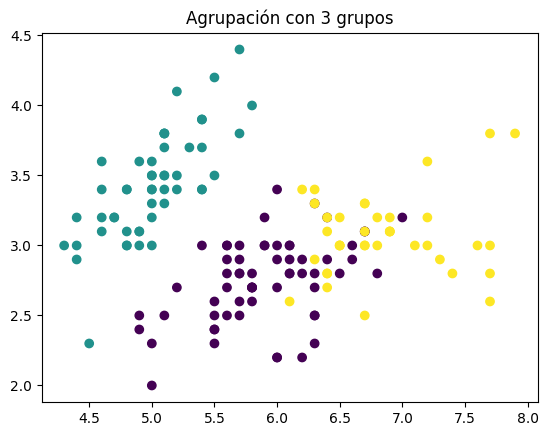

In [59]:
import matplotlib.pyplot as plt

plt.scatter(datos[:, 0], datos[:, 1], c=modelo.labels_, cmap="viridis")
plt.title(f"Agrupación con {n_clusters} grupos")
plt.show()

In [60]:
# prueba el código con 2 grupos

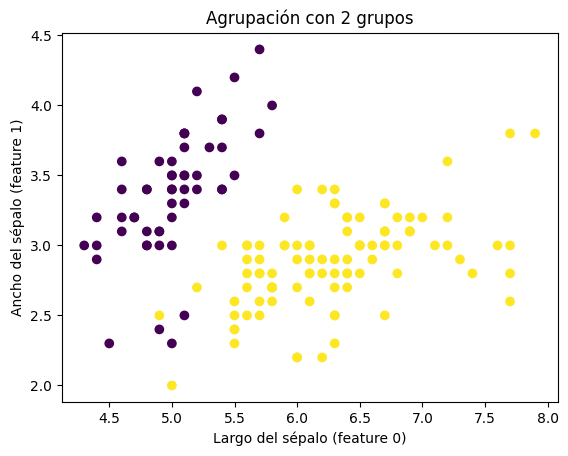

Tabla de Contingencia:
col_0     0   1
species        
0        50   0
1         3  47
2         0  50

Total de flores: 150
Fallos totales: 50
Porcentaje de acierto: 66.67 %
setosa -> fallos: 0 de 50 ( 0.0 % )
versicolor -> fallos: 50 de 50 ( 100.0 % )
virginica -> fallos: 0 de 50 ( 0.0 % )

Muestras mal clasificadas:


,species_name,cluster_corregido
50,versicolor,virginica
51,versicolor,virginica
52,versicolor,virginica
53,versicolor,virginica
54,versicolor,virginica
55,versicolor,virginica
56,versicolor,virginica
57,versicolor,setosa
58,versicolor,virginica
59,versicolor,virginica


In [85]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

n_clusters_2 = 2

modelo_2 = KMeans(n_clusters=n_clusters_2, random_state=0, n_init=10)
modelo_2.fit(datos)

plt.scatter(datos[:, 0], datos[:, 1], c=modelo_2.labels_, cmap="viridis")
plt.title(f"Agrupación con {n_clusters_2} grupos")
plt.xlabel("Largo del sépalo (feature 0)")
plt.ylabel("Ancho del sépalo (feature 1)")
plt.show()

contingency_matrix = pd.crosstab(tabla['species'], modelo_2.labels_)
print("Tabla de Contingencia:")
print(contingency_matrix)
print("\n" + "="*40)

real_classes = tabla['species'].values
predicted_clusters = modelo_2.labels_

cluster_to_species_map = {}
for c in range(n_clusters_2):
    clase_mayoritaria = contingency_matrix[c].idxmax() if c in contingency_matrix.columns else -1
    cluster_to_species_map[c] = clase_mayoritaria

cluster_corregido = np.array([cluster_to_species_map[c] for c in predicted_clusters])

total_flores = len(tabla)
aciertos = np.sum(real_classes == cluster_corregido)
fallos_totales = total_flores - aciertos
porcentaje_acierto = (aciertos / total_flores) * 100

print(f"Total de flores: {total_flores}")
print(f"Fallos totales: {fallos_totales}")
print(f"Porcentaje de acierto: {porcentaje_acierto:.2f} %")

for r in range(3):
    name = iris.target_names[r]
    total_esp = np.sum(real_classes == r)
    correct_esp = np.sum((real_classes == r) & (cluster_corregido == r))
    fallos_esp = total_esp - correct_esp
    pct_fallos = (fallos_esp / total_esp) * 100
    print(f"{name} -> fallos: {fallos_esp} de {total_esp} ( {pct_fallos:.1f} % )")

tabla_metricas = pd.DataFrame({
    'species_name': tabla['species_name'],
    'cluster_corregido': [iris.target_names[c] for c in cluster_corregido]
})

print("\nMuestras mal clasificadas:")
display(tabla_metricas[real_classes != cluster_corregido])

In [62]:
# prueba el código con 4 grupos

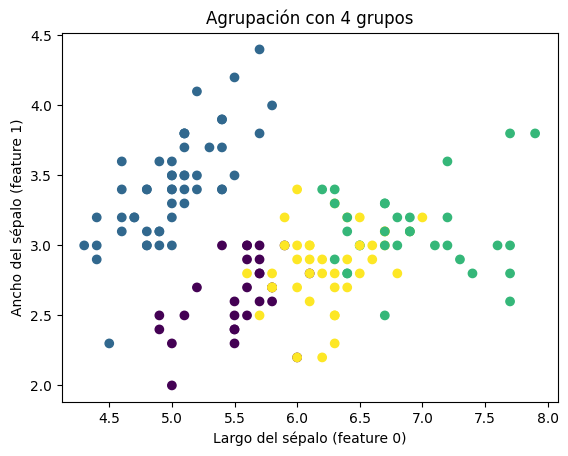

Tabla de Contingencia:
col_0     0   1   2   3
species                
0         0  50   0   0
1        27   0   0  23
2         1   0  32  17

Total de flores: 150
Fallos totales: 18
Porcentaje de acierto: 88.00 %
setosa -> fallos: 0 de 50 ( 0.0 % )
versicolor -> fallos: 0 de 50 ( 0.0 % )
virginica -> fallos: 18 de 50 ( 36.0 % )

Muestras mal clasificadas:


,species_name,cluster_corregido
101,virginica,versicolor
106,virginica,versicolor
110,virginica,versicolor
111,virginica,versicolor
113,virginica,versicolor
114,virginica,versicolor
119,virginica,versicolor
121,virginica,versicolor
123,virginica,versicolor
126,virginica,versicolor


In [81]:
# === Configuración para 4 grupos ===
n_clusters_4 = 4
modelo_4 = KMeans(n_clusters=n_clusters_4, random_state=0, n_init=10)
modelo_4.fit(datos)

plt.scatter(datos[:, 0], datos[:, 1], c=modelo_4.labels_, cmap="viridis")
plt.title(f"Agrupación con {n_clusters_4} grupos")
plt.xlabel("Largo del sépalo (feature 0)")
plt.ylabel("Ancho del sépalo (feature 1)")
plt.show()

contingency_matrix = pd.crosstab(tabla['species'], modelo_4.labels_)
print("Tabla de Contingencia:")
print(contingency_matrix)
print("\n" + "="*40)

real_classes = tabla['species'].values
predicted_clusters = modelo_4.labels_

cluster_to_species_map = {}
for c in range(n_clusters_4):
    clase_mayoritaria = contingency_matrix[c].idxmax() if c in contingency_matrix.columns else -1
    cluster_to_species_map[c] = clase_mayoritaria

cluster_corregido = np.array([cluster_to_species_map[c] for c in predicted_clusters])

total_flores = len(tabla)
aciertos = np.sum(real_classes == cluster_corregido)
fallos_totales = total_flores - aciertos
porcentaje_acierto = (aciertos / total_flores) * 100

print(f"Total de flores: {total_flores}")
print(f"Fallos totales: {fallos_totales}")
print(f"Porcentaje de acierto: {porcentaje_acierto:.2f} %")

for r in range(3):
    name = iris.target_names[r]
    total_esp = np.sum(real_classes == r)
    correct_esp = np.sum((real_classes == r) & (cluster_corregido == r))
    fallos_esp = total_esp - correct_esp
    pct_fallos = (fallos_esp / total_esp) * 100
    print(f"{name} -> fallos: {fallos_esp} de {total_esp} ( {pct_fallos:.1f} % )")

tabla_metricas = pd.DataFrame({
    'species_name': tabla['species_name'],
    'cluster_corregido': [iris.target_names[c] for c in cluster_corregido]
})

print("\nMuestras mal clasificadas:")
display(tabla_metricas[real_classes != cluster_corregido])

In [64]:
# prueba el código con 5 grupos

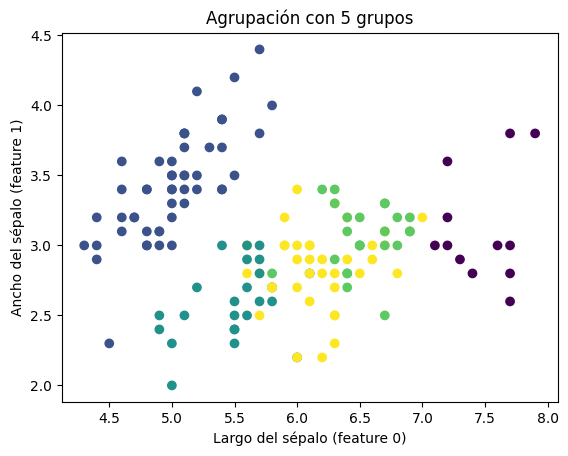

Tabla de Contingencia:
col_0     0   1   2   3   4
species                    
0         0  50   0   0   0
1         0   0  24   0  26
2        12   0   1  24  13

Total de flores: 150
Fallos totales: 14
Porcentaje de acierto: 90.67 %
setosa -> fallos: 0 de 50 ( 0.0 % )
versicolor -> fallos: 0 de 50 ( 0.0 % )
virginica -> fallos: 14 de 50 ( 28.0 % )

Muestras mal clasificadas:


,species_name,cluster_corregido
101,virginica,versicolor
106,virginica,versicolor
113,virginica,versicolor
119,virginica,versicolor
121,virginica,versicolor
123,virginica,versicolor
126,virginica,versicolor
127,virginica,versicolor
133,virginica,versicolor
134,virginica,versicolor


In [86]:
# === Configuración para 5 grupos ===
n_clusters_5 = 5
modelo_5 = KMeans(n_clusters=n_clusters_5, random_state=0, n_init=10)
modelo_5.fit(datos)

plt.scatter(datos[:, 0], datos[:, 1], c=modelo_5.labels_, cmap="viridis")
plt.title(f"Agrupación con {n_clusters_5} grupos")
plt.xlabel("Largo del sépalo (feature 0)")
plt.ylabel("Ancho del sépalo (feature 1)")
plt.show()

contingency_matrix = pd.crosstab(tabla['species'], modelo_5.labels_)
print("Tabla de Contingencia:")
print(contingency_matrix)
print("\n" + "="*40)

real_classes = tabla['species'].values
predicted_clusters = modelo_5.labels_

cluster_to_species_map = {}
for c in range(n_clusters_5):
    clase_mayoritaria = contingency_matrix[c].idxmax() if c in contingency_matrix.columns else -1
    cluster_to_species_map[c] = clase_mayoritaria

cluster_corregido = np.array([cluster_to_species_map[c] for c in predicted_clusters])

total_flores = len(tabla)
aciertos = np.sum(real_classes == cluster_corregido)
fallos_totales = total_flores - aciertos
porcentaje_acierto = (aciertos / total_flores) * 100

print(f"Total de flores: {total_flores}")
print(f"Fallos totales: {fallos_totales}")
print(f"Porcentaje de acierto: {porcentaje_acierto:.2f} %")

for r in range(3):
    name = iris.target_names[r]
    total_esp = np.sum(real_classes == r)
    correct_esp = np.sum((real_classes == r) & (cluster_corregido == r))
    fallos_esp = total_esp - correct_esp
    pct_fallos = (fallos_esp / total_esp) * 100
    print(f"{name} -> fallos: {fallos_esp} de {total_esp} ( {pct_fallos:.1f} % )")

tabla_metricas = pd.DataFrame({
    'species_name': tabla['species_name'],
    'cluster_corregido': [iris.target_names[c] for c in cluster_corregido]
})

print("\nMuestras mal clasificadas:")
display(tabla_metricas[real_classes != cluster_corregido])

**K-Means sirve para datos sin etiquetar, ¿qué datos reales llegan sin etiquetar en el mundo profesional?**

En el mundo profesional, la gran mayoría de los datos se generan de forma automatizada y masiva sin una etiqueta o categoría predefinida. Algunos de los ejemplos reales más comunes incluyen:

1. **Datos de clientes y comportamiento de compra (Marketing / Retail):**
   * Historiales de transacciones, frecuencia de compra y montos gastados. No vienen con etiquetas de "cliente fiel" o "comprador impulsivo"; se utiliza K-Means para descubrir estos segmentos de clientes de forma automática (segmentación de clientes o *Customer Segmentation*).

2. **Datos de navegación web y registros (Logs):**
   * Rutas de clics, tiempo de permanencia en páginas y acciones realizadas por usuarios en una plataforma. Estos datos se agrupan para identificar patrones de comportamiento comunes u optimizar la experiencia de usuario (UX).

3. **Transacciones financieras para detección de anomalías:**
   * Las operaciones bancarias diarias no vienen etiquetadas como "fraude" o "legítima". Al agrupar el comportamiento transaccional normal, los puntos o transacciones que quedan muy alejados de los clústeres principales se detectan como anomalías.

4. **Datos de sensores en Internet de las Cosas (IoT) e Industria:**
   * Mediciones de temperatura, vibración o presión de maquinaria en tiempo real. Agrupar estos datos permite identificar estados de funcionamiento óptimos versus patrones inusuales que alerten sobre la necesidad de mantenimiento preventivo.

5. **Textos y documentos de soporte / redes sociales:**
   * Correos de soporte técnico, comentarios en redes sociales o noticias de actualidad. No vienen categorizados por temas de origen; algoritmos de clustering ayudan a agruparlos automáticamente en temáticas o tópicos comunes (*Topic Modeling*).

El tipo de dato **numpy.ndarray** es un array de **NumPy**, para extraer fragmentos de datos debes usar coordenadas dentro de corchetes con la estructura:

datos[filas, columnas]

Los datos se pueden guardar en un array estructurado como si fuera una tabla de Excel con nombres en las columnas, lo ideal es transformarlo en un **DataFrame de Pandas**.


El tipo de dato **numpy.ndarray** es un array de **NumPy**, para extraer fragmentos de datos debes usar coordenadas dentro de corchetes con la estructura:

datos[filas, columnas]

Los datos se pueden guardar en un array estructurado como si fuera una tabla de Excel con nombres en las columnas, lo ideal es transformarlo en un **DataFrame de Pandas**.


In [66]:
import pandas as pd

tabla = pd.DataFrame(datos, columns=iris.feature_names)
print(tabla.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [67]:
# también se puede importar los datos directamente,
# pero así no se dispone de los nombres de las columnas
tabla2 = pd.DataFrame(datos)
print(tabla2.head())

     0    1    2    3
0  5.1  3.5  1.4  0.2
1  4.9  3.0  1.4  0.2
2  4.7  3.2  1.3  0.2
3  4.6  3.1  1.5  0.2
4  5.0  3.6  1.4  0.2


In [68]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [69]:
tabla.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [70]:
tabla['petal length (cm)']

,petal length (cm)
0,1.4
1,1.4
2,1.3
3,1.5
4,1.4
...,...
145,5.2
146,5.0
147,5.2
148,5.4


In [71]:
flores_grandes = tabla[tabla['petal length (cm)'] > 5]
flores_grandes

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
83,6.0,2.7,5.1,1.6
100,6.3,3.3,6.0,2.5
101,5.8,2.7,5.1,1.9
102,7.1,3.0,5.9,2.1
103,6.3,2.9,5.6,1.8
104,6.5,3.0,5.8,2.2
105,7.6,3.0,6.6,2.1
107,7.3,2.9,6.3,1.8
108,6.7,2.5,5.8,1.8
109,7.2,3.6,6.1,2.5


In [72]:
# aquí se agregan tres columnas que representan el código de la especie,
# el nombre de la especie a la tabla y el código del cluster asignado
tabla['species'] = iris.target
tabla['species_name'] = tabla['species'].map(lambda x: iris.target_names[x])
tabla['cluster'] = modelo.labels_

In [73]:
tabla

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name,cluster
0,5.1,3.5,1.4,0.2,0,setosa,1
1,4.9,3.0,1.4,0.2,0,setosa,1
2,4.7,3.2,1.3,0.2,0,setosa,1
3,4.6,3.1,1.5,0.2,0,setosa,1
4,5.0,3.6,1.4,0.2,0,setosa,1
...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,virginica,2
146,6.3,2.5,5.0,1.9,2,virginica,0
147,6.5,3.0,5.2,2.0,2,virginica,2
148,6.2,3.4,5.4,2.3,2,virginica,2


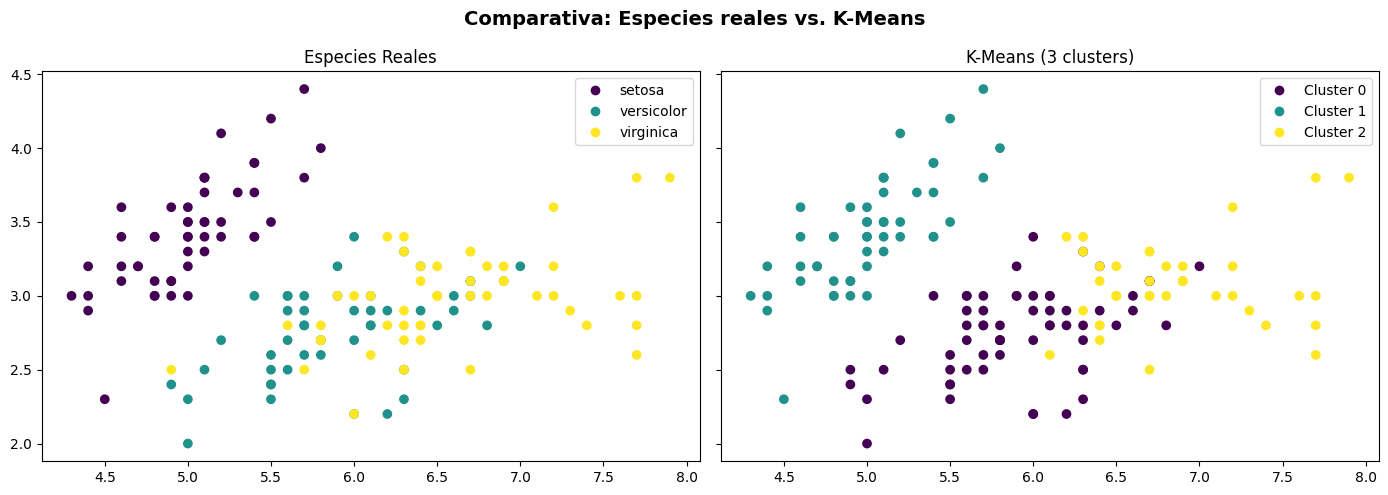

In [74]:
# para comparar el resultado con las especies realesn_clusters = 3

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

scatter1 = ax1.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['species'],
    cmap='viridis'
)
ax1.set_title("Especies Reales")
ax1.legend(handles=scatter1.legend_elements()[0], labels=list(iris.target_names))

scatter2 = ax2.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['cluster'],
    cmap='viridis'
)
ax2.set_title(f"K-Means ({n_clusters} clusters)")
ax2.legend(handles=scatter2.legend_elements()[0], labels=[f'Cluster {i}' for i in range(n_clusters)])

plt.suptitle("Comparativa: Especies reales vs. K-Means", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [75]:
# para comparar el resultado con las especies reales
print(modelo.labels_)
print(iris.target)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


Implementa una comparación entre los resultados obtenidos y los resultados reales.

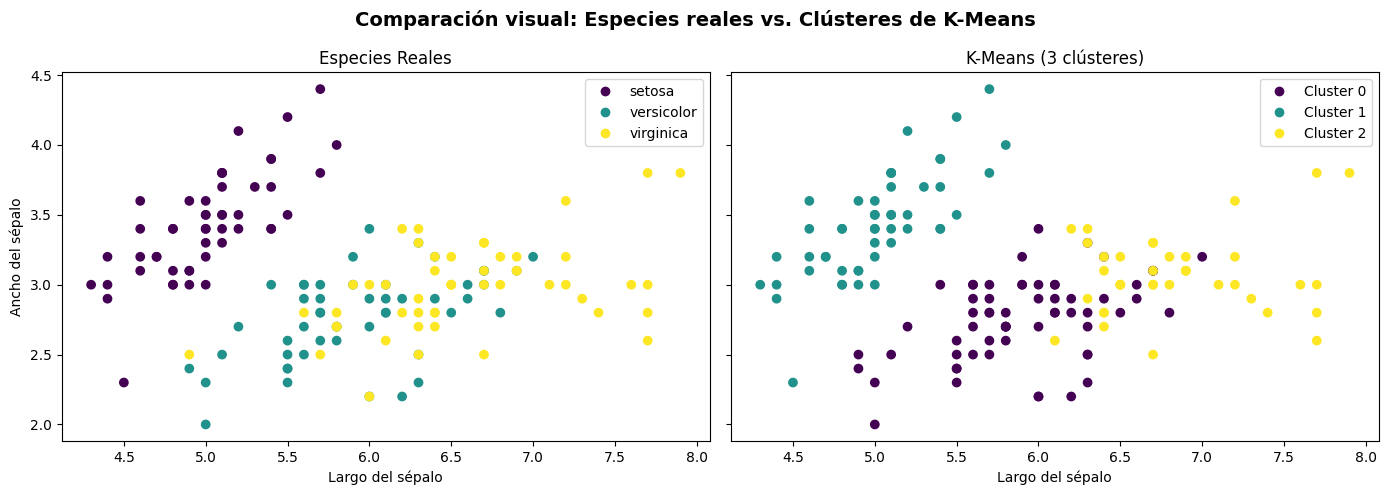

In [76]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

scatter1 = ax1.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['species'],
    cmap='viridis'
)
ax1.set_title("Especies Reales")
ax1.set_xlabel("Largo del sépalo")
ax1.set_ylabel("Ancho del sépalo")
ax1.legend(handles=scatter1.legend_elements()[0], labels=list(iris.target_names))

scatter2 = ax2.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['cluster'],
    cmap='viridis'
)
ax2.set_title(f"K-Means ({n_clusters} clústeres)")
ax2.set_xlabel("Largo del sépalo")
ax2.legend(handles=scatter2.legend_elements()[0], labels=[f'Cluster {i}' for i in range(n_clusters)])

plt.suptitle("Comparación visual: Especies reales vs. Clústeres de K-Means", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()